# Sampling directional runs by information

Positive and negative contributions are accumulated separately, and the run measure keeps the larger total:

$$
x_i^+=\max(x_i,0),\qquad x_i^-=\max(-x_i,0),\qquad
R_n=\max\left\{\sum_{i=1}^{n}x_i^+,\sum_{i=1}^{n}x_i^-\right\}.
$$

Here, $x_i$ is a signed contribution; $x_i^+$ is its positive part; $x_i^-$ is the magnitude of its negative part. $n$ is the current record count; $R_n$ is the larger of cumulative positive and cumulative negative contributions.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("05_event_based_financial_time");
using CSV, Printf
using RiskLabAI.Data: StandardBars,TimeBars,FixedImbalanceBars,ExpectedImbalanceBars,FixedRunBars,ExpectedRunBars,Tick,Volume,Dollar,construct_bars_from_data
using RiskLabAI.Utils: CUMULATIVE_TICKS,CUMULATIVE_THETA,EXPECTED_IMBALANCE,EXPECTED_TICKS_NUMBER,CUMULATIVE_BUY_THETA,CUMULATIVE_SELL_THETA,EXPECTED_BUY_IMBALANCE,EXPECTED_SELL_IMBALANCE,EXPECTED_BUY_TICKS_PROPORTION
raw_all = load_binance()
raw = first(raw_all,10080)
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
observations = select(raw,:time,:close,:volume)
bar_columns = ["Time","Last record","Open","High","Low","Close","Volume","Buy volume","Sell volume","Records","Dollar value","Rule level"]

function bar_frame(rows)
    return DataFrame([name=>(j==1 ? DateTime[row[j] for row in rows] : j in (2,10) ? Int[row[j] for row in rows] : Float64[row[j] for row in rows]) for (j,name) in enumerate(bar_columns)])
end

function history_frame(rule,names)
    history = rule.analyse_thresholds
    columns = Pair["Record"=>collect(eachindex(history))]
    append!(columns,[name=>Float64[row[name] for row in history] for name in names])
    return DataFrame(columns)
end


history_frame (generic function with 1 method)

## How signed ticks cancel or accumulate

Imbalance lets opposite signs cancel, while the run measure keeps positive and negative accumulation separate:

$$
\theta_n=\sum_{i=1}^{n}x_i,\qquad
R_n=\max\left\{\sum_{i=1}^{n}x_i^+,\sum_{i=1}^{n}x_i^-\right\}.
$$

Here, $\theta_n$ is net imbalance through record $n$; $x_i$ is a signed contribution; $x_i^+,x_i^-$ are its positive and negative parts. $R_n$ is the larger one-sided accumulated total; $i$ labels records; $n$ is the current record count.

Row,Quantity,Value
,String,Int64
1,Final net imbalance,0
2,Largest absolute net imbalance,6
3,Final positive count,12
4,Final negative count,12
5,Final run measure,12


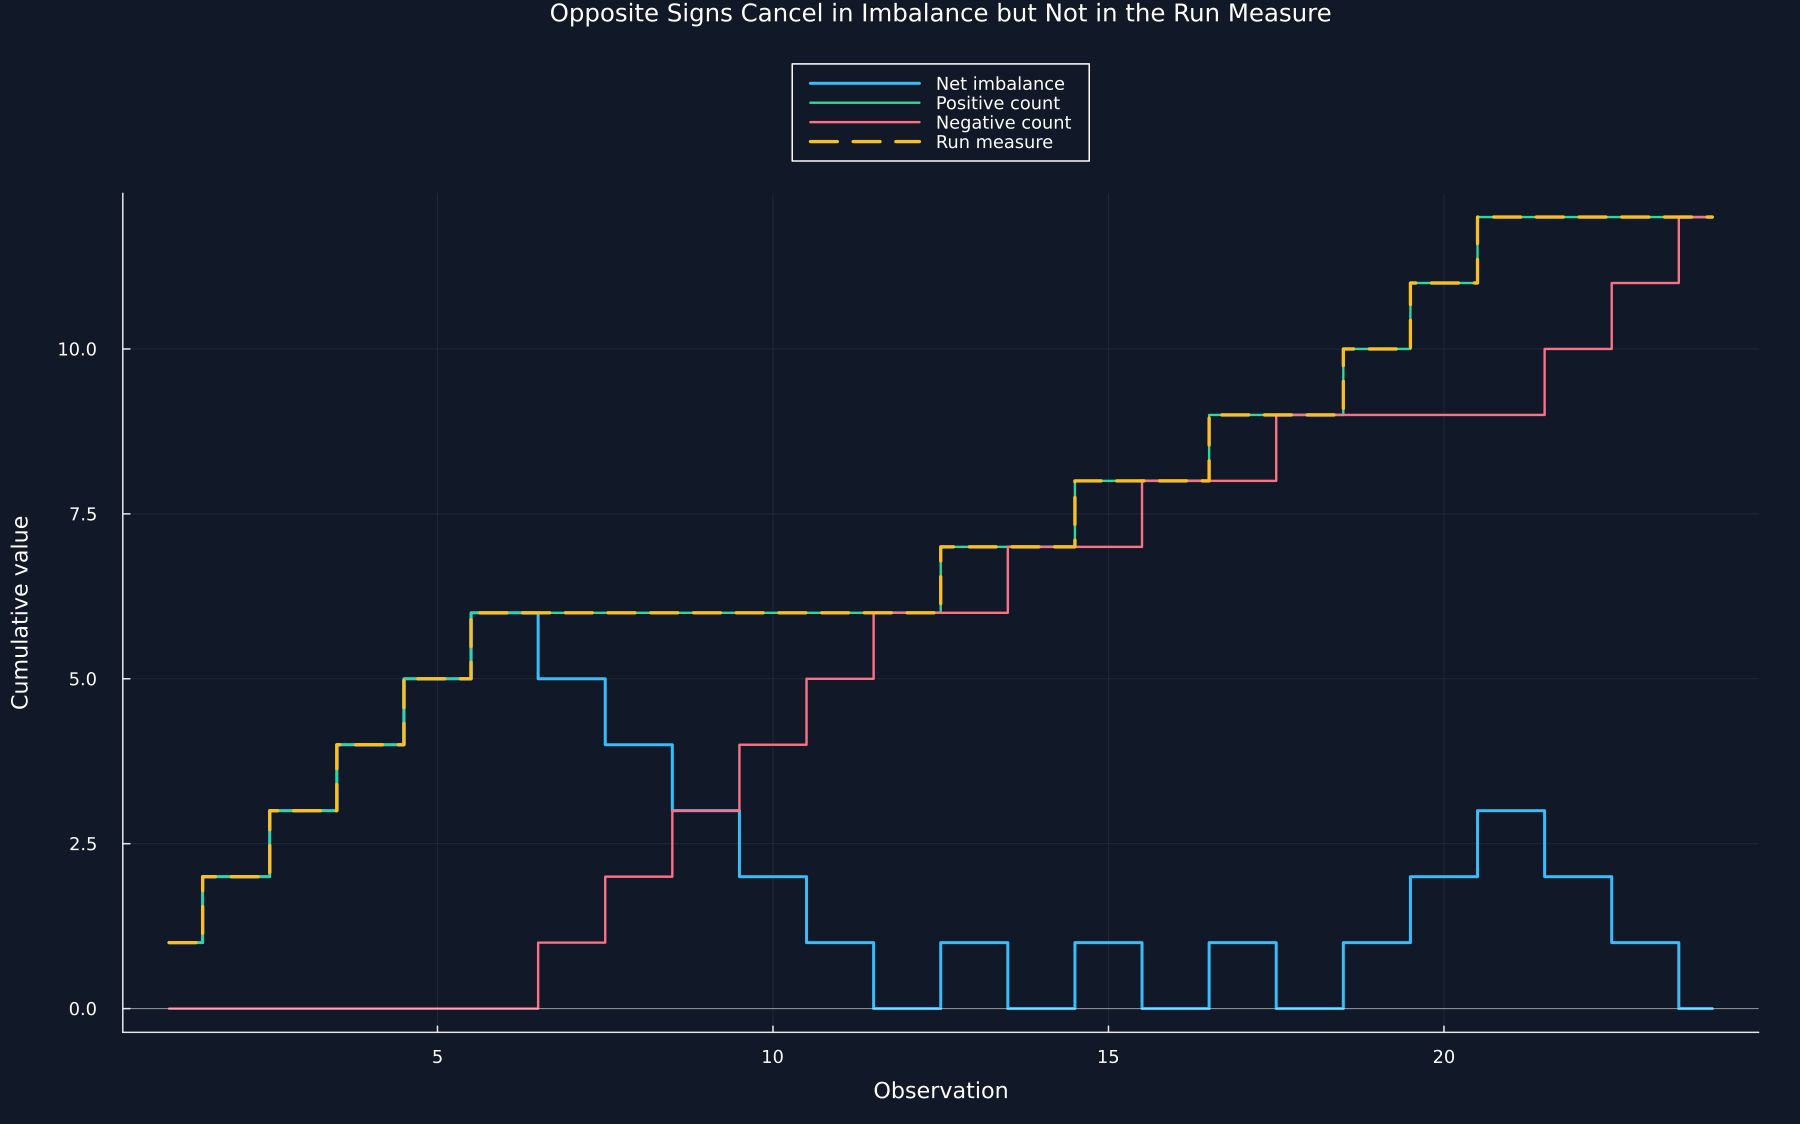

In [2]:
signs = [1,1,1,1,1,1,-1,-1,-1,-1,-1,-1,1,-1,1,-1,1,-1,1,1,1,-1,-1,-1]
net_imbalance = cumsum(signs)
positive_count,negative_count = cumsum(signs.>0),cumsum(signs.<0)
run_measure = max.(positive_count,negative_count)
controlled_comparison = DataFrame("Quantity"=>["Final net imbalance","Largest absolute net imbalance","Final positive count","Final negative count","Final run measure"],"Value"=>[last(net_imbalance),maximum(abs.(net_imbalance)),last(positive_count),last(negative_count),last(run_measure)])
save_table(controlled_comparison,paths,"controlled_run_comparison";caption="Net imbalance permits cancellation, while the run measure keeps the two sides separate.",label="tab:controlled-run-comparison")
positions = collect(eachindex(signs))
figure = plot(;xlabel="Observation",ylabel="Cumulative value",title="Opposite Signs Cancel in Imbalance but Not in the Run Measure",legend=:outertop,size=(1200,750))
for (values,color,width,label) in [(net_imbalance,palette.cyan,2.,"Net imbalance"),(positive_count,palette.green,1.6,"Positive count"),(negative_count,palette.rose,1.6,"Negative count"),(run_measure,palette.amber,2.2,"Run measure")]
    plot!(figure,positions,values;seriestype=:stepmid,color,linewidth=width,linestyle=label=="Run measure" ? :dash : :solid,label)
end
hline!(figure,[0.];color=palette.text,linewidth=.7,alpha=.55,label=false)
save_figure(figure,paths,"imbalance_and_run_paths")
save_data(DataFrame("Record"=>positions,"Sign"=>signs,"Net imbalance"=>net_imbalance,"Positive count"=>positive_count,"Negative count"=>negative_count,"Run measure"=>run_measure),paths,"controlled_run_paths");


## Run-Bar Rule

A run bar closes when the larger one-sided total first reaches its expected scale:

$$
\tau=\inf\left\{n\geq1:R_n\geq \widehat T\max\left(\widehat p_+\widehat\mu_+,(1-\widehat p_+)\widehat\mu_-\right)\right\}.
$$

Here, $\tau$ is the closing record; $n$ is a candidate record count; $R_n$ is the run measure; $\widehat T$ is expected bar length. $\widehat p_+$ is the estimated chance of a positive contribution; $\widehat\mu_+,\widehat\mu_-$ are estimated positive and negative magnitudes. $\max$ selects the larger expected one-sided rate; $\inf$ selects the first threshold crossing.

In [3]:
fixed_run_rule = FixedRunBars{Tick}(;bar_type="tick_run",initial_estimate_of_expected_n_ticks_in_bar=120.,expected_imbalance_window=240,does_analyse_thresholds=true)
expected_run_rule = ExpectedRunBars{Tick}(;bar_type="tick_run",window_size_for_expected_n_ticks_estimation=20,initial_estimate_of_expected_n_ticks_in_bar=60.,expected_imbalance_window=240,expected_ticks_number_bounds=(20.,180.),does_analyse_thresholds=true)
fixed_run_bars = bar_frame(construct_bars_from_data(fixed_run_rule;data=observations))
expected_run_bars = bar_frame(construct_bars_from_data(expected_run_rule;data=observations))
history_names = [EXPECTED_TICKS_NUMBER,EXPECTED_BUY_TICKS_PROPORTION,EXPECTED_BUY_IMBALANCE,EXPECTED_SELL_IMBALANCE,CUMULATIVE_BUY_THETA,CUMULATIVE_SELL_THETA,CUMULATIVE_TICKS]
fixed_run_history,expected_run_history = history_frame(fixed_run_rule,history_names),history_frame(expected_run_rule,history_names)
summary_rows = [(;rule=name,complete=nrow(frame),smallest=minimum(frame.Records),middle=median(frame.Records),largest=maximum(frame.Records),buy_share=median(frame[!,"Buy volume"]./frame.Volume)) for (name,frame) in [("Fixed expected length",fixed_run_bars),("Updated expected length",expected_run_bars)]]
run_bar_summary = DataFrame(summary_rows)
rename!(run_bar_summary,["Rule","Complete bars","Smallest record count","Middle record count","Largest record count","Middle buy share"])
save_table(run_bar_summary,paths,"run_bar_summary";caption="Tick-run bars formed from the one-week illustration.",label="tab:run-bar-summary")
save_data(fixed_run_bars,paths,"fixed_run_bars")
save_data(expected_run_bars,paths,"expected_run_bars")
save_data(fixed_run_history,paths,"fixed_run_history")
save_data(expected_run_history,paths,"expected_run_history");


Row,Rule,Complete bars,Smallest record count,Middle record count,Largest record count,Middle buy share
,String,Int64,Int64,Float64,Int64,Float64
1,Fixed expected length,86,96,116.0,244,0.507894
2,Updated expected length,109,54,90.0,127,0.510073


## Comparing imbalance bars with run bars

For two nonnegative totals, their absolute difference cannot exceed the larger total, which cannot exceed their sum:

$$
|a-b|\leq \max(a,b)\leq a+b\qquad(a,b\geq0).
$$

Here, $a\geq0$ and $b\geq0$ are nonnegative quantities; $|a-b|$ is their absolute difference; $\max(a,b)$ is the larger one.

Row,Rule,Complete bars,10th percentile records,Middle records,90th percentile records,Records used by complete bars
,String,Int64,Float64,Float64,Float64,Int64
1,Fixed tick imbalance,173,1.0,12.0,206.0,9946
2,Fixed tick run,86,107.0,116.0,121.0,9998


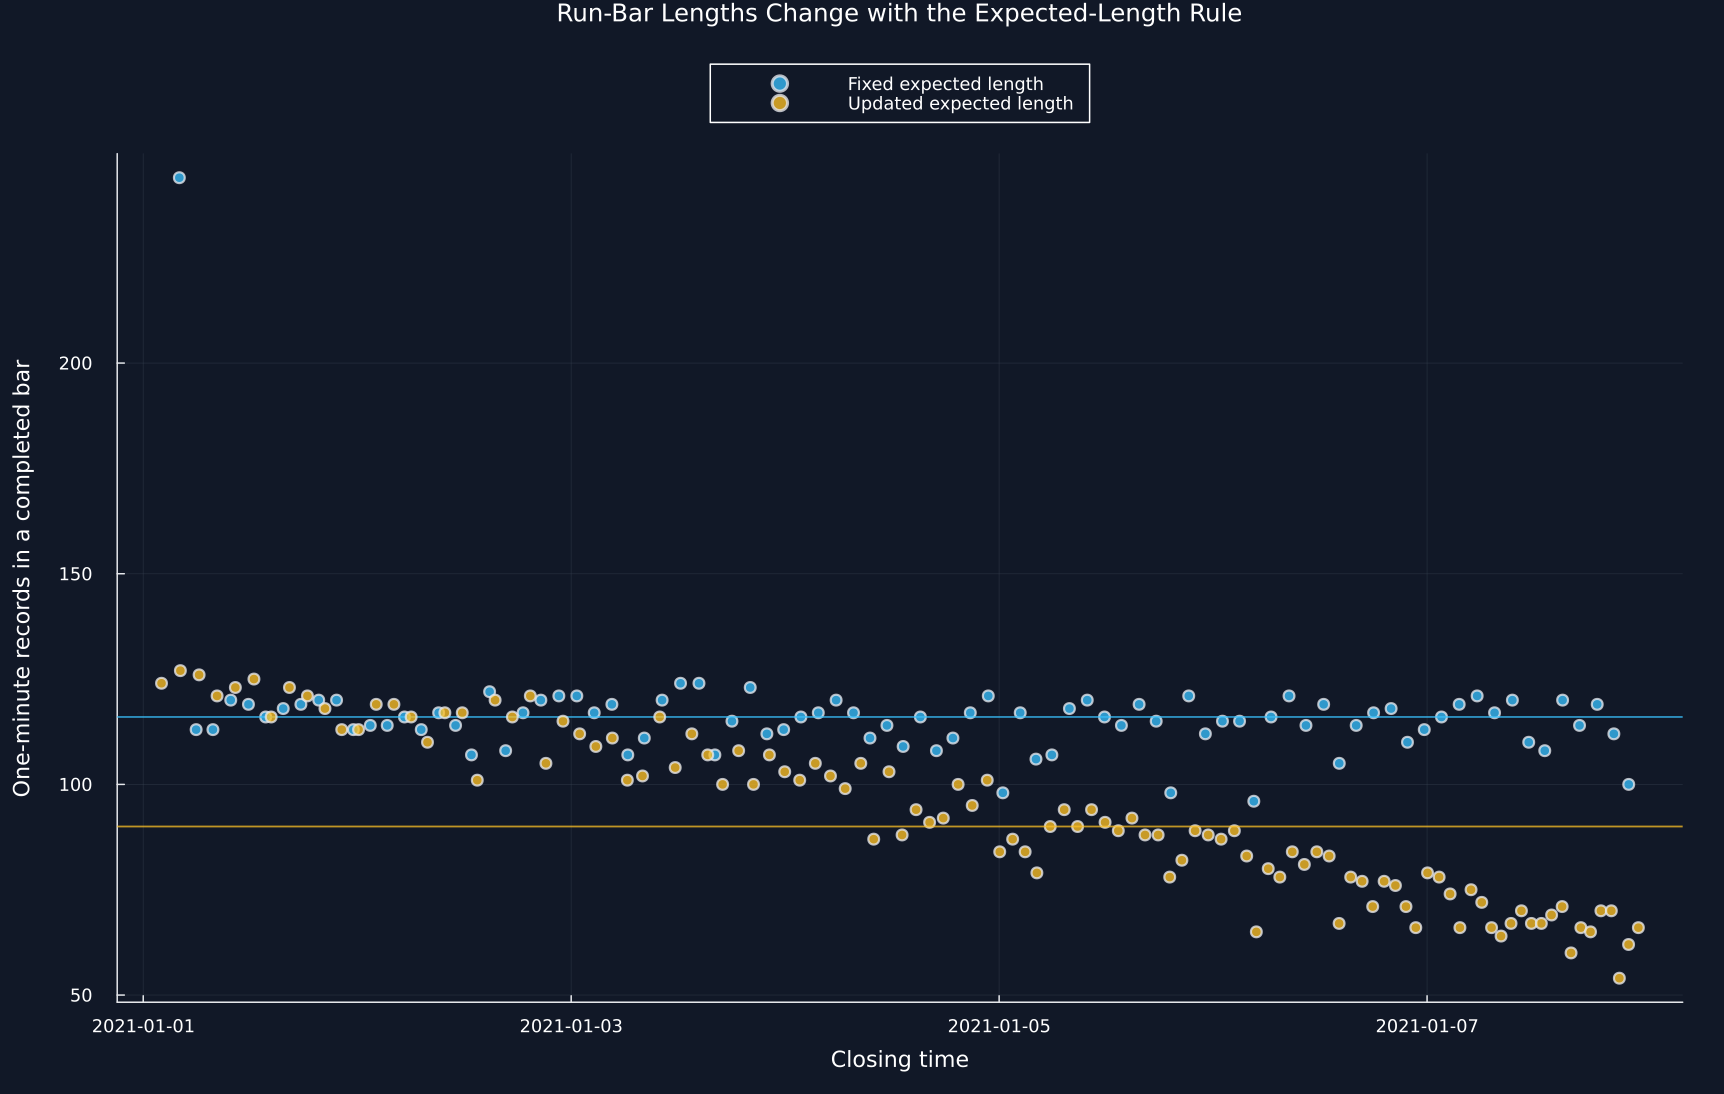

In [4]:
fixed_imbalance_rule = FixedImbalanceBars{Tick}(;bar_type="tick_imbalance",initial_estimate_of_expected_n_ticks_in_bar=120.,expected_imbalance_window=240)
fixed_imbalance_bars = bar_frame(construct_bars_from_data(fixed_imbalance_rule;data=observations))
comparison_rows = [(;rule=name,complete=nrow(frame),lower=quantile(frame.Records,.10),middle=median(frame.Records),upper=quantile(frame.Records,.90),used=sum(frame.Records)) for (name,frame) in [("Fixed tick imbalance",fixed_imbalance_bars),("Fixed tick run",fixed_run_bars)]]
imbalance_run_comparison = DataFrame(comparison_rows)
rename!(imbalance_run_comparison,["Rule","Complete bars","10th percentile records","Middle records","90th percentile records","Records used by complete bars"])
save_table(imbalance_run_comparison,paths,"imbalance_run_comparison";caption="Fixed tick-imbalance and tick-run rules applied to the same records.",label="tab:imbalance-run-comparison")
save_data(fixed_imbalance_bars,paths,"comparison_imbalance_bars")
figure = plot(;xlabel="Closing time",ylabel="One-minute records in a completed bar",title="Run-Bar Lengths Change with the Expected-Length Rule",legend=:outertop,size=(1150,730))
for (frame,color,label) in [(fixed_run_bars,palette.cyan,"Fixed expected length"),(expected_run_bars,palette.amber,"Updated expected length")]
    scatter!(figure,frame.Time,frame.Records;color,markersize=4,alpha=.78,label)
    hline!(figure,[median(frame.Records)];color,linewidth=1.2,alpha=.75,label=false)
end
save_figure(figure,paths,"run_bar_lengths")


In [5]:
fixed_close_positions = fixed_run_bars[!,"Last record"]
close_crossings,previous_steps_below = Bool[],Bool[]
bar_start = 1
for close_position in fixed_close_positions
    row = fixed_run_history[close_position,:]
    boundary = row[EXPECTED_TICKS_NUMBER]*max(row[EXPECTED_BUY_TICKS_PROPORTION]*row[EXPECTED_BUY_IMBALANCE],(1-row[EXPECTED_BUY_TICKS_PROPORTION])*row[EXPECTED_SELL_IMBALANCE])
    run_value = max(row[CUMULATIVE_BUY_THETA],row[CUMULATIVE_SELL_THETA])
    push!(close_crossings,run_value>=boundary)
    if close_position>bar_start
        prior = fixed_run_history[close_position-1,:]
        prior_inputs = [prior[key] for key in [EXPECTED_TICKS_NUMBER,EXPECTED_BUY_TICKS_PROPORTION,EXPECTED_BUY_IMBALANCE,EXPECTED_SELL_IMBALANCE]]
        if all(isfinite,prior_inputs)
            prior_boundary = prior[EXPECTED_TICKS_NUMBER]*max(prior[EXPECTED_BUY_TICKS_PROPORTION]*prior[EXPECTED_BUY_IMBALANCE],(1-prior[EXPECTED_BUY_TICKS_PROPORTION])*prior[EXPECTED_SELL_IMBALANCE])
            prior_value = max(prior[CUMULATIVE_BUY_THETA],prior[CUMULATIVE_SELL_THETA])
            push!(previous_steps_below,prior_value<prior_boundary)
        else
            push!(previous_steps_below,true)
        end
    end
    bar_start = close_position+1
end


## Tests

In [6]:
@assert length(signs) == 24
@assert last(net_imbalance) == 0
@assert last(run_measure) == 12
@assert all(diff(positive_count).>=0)
@assert all(diff(negative_count).>=0)
@assert all(diff(run_measure).>=0)
@assert all(abs.(net_imbalance).<=run_measure)
@assert nrow(fixed_run_history) == nrow(raw)
@assert nrow(expected_run_history) == nrow(raw)
@assert nrow(fixed_run_bars) == 86
@assert nrow(expected_run_bars) == 109
@assert nrow(fixed_imbalance_bars) == 173
@assert all(close_crossings)
@assert all(previous_steps_below)
@assert minimum(fixed_run_bars.Records) >= 1
@assert minimum(expected_run_bars.Records) >= 1
@assert all(fixed_run_bars[!,"Rule level"].>0)
@assert all(expected_run_bars[!,"Rule level"].>0)
@assert all(filter(isfinite,fixed_run_history[!,EXPECTED_TICKS_NUMBER]).==120)
@assert all(20 .<= filter(isfinite,expected_run_history[!,EXPECTED_TICKS_NUMBER]) .<= 180)
@assert isfile(joinpath(paths.figures,"imbalance_and_run_paths.pdf"))
@assert isfile(joinpath(paths.figures,"run_bar_lengths.pdf"))
@assert isfile(joinpath(paths.tables,"controlled_run_comparison.tex"))
@assert isfile(joinpath(paths.tables,"run_bar_summary.tex"))
@assert isfile(joinpath(paths.tables,"imbalance_run_comparison.tex"))
